# tilizando el conjunto de datos “Life expectancy”
* a. Realizar todo el preprocesamiento necesario sobre todas las columnas.
* b. Comprobar gráfica y estadísticamente si los países desarrollados tienen un
producto per cápita mayor al de los en vías de desarrollo. Seleccionar el
mejor test en función del objetivo y el cumplimiento de los supuestos.
* c. Comprobar gráfica y estadísticamente si los países en vías de desarrollo
gastan un menor porcentaje de su producto bruto en salud que los países
desarrollados. Seleccionar el mejor test en función del objetivo y el
cumplimiento de los supuestos.
* d. Comprobar gráfica y estadísticamente si los países en vías de desarrollo
tienen una expectativa de vida menor a los desarrollados.
* e. ¿Hay una relación entre la combinación de las variables producto per cápita y
porcentaje del producto per cápita invertido en salud y la expectativa de vida?
Seleccionar la mejor estrategia para aproximar esta conclusión.


In [1]:
pip install wget

Note: you may need to restart the kernel to use updated packages.


In [8]:
import wget
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler

from os import path

# inicializamos un diccionario donde guardaremos el dataset
dataset = dict()
dataset['url'] = 'https://ignaciorlando.github.io/datasets/data-science/Life-Expectancy-Data-Updated.csv'
dataset['extension'] = '.csv'
dataset['filename'] = 'life_expectancy' + dataset['extension']
!rm -rf {dataset['filename']}
wget.download(dataset['url'], dataset['filename'])

# accedemos a los datos usando Pandas
original_table = pd.read_table(dataset['filename'],sep=',')
original_table.head()


"rm" no se reconoce como un comando interno o externo,
programa o archivo por lotes ejecutable.


,Country,Region,Year,Infant_deaths,Under_five_deaths,Adult_mortality,Alcohol_consumption,Hepatitis_B,Measles,BMI,...,Diphtheria,Incidents_HIV,GDP_per_capita,Population_mln,Thinness_ten_nineteen_years,Thinness_five_nine_years,Schooling,Economy_status_Developed,Economy_status_Developing,Life_expectancy
0,Turkiye,Middle East,2015,11.1,13.0,105.8240,1.32,97,65,27.8,...,97,0.08,11006,78.53,4.9,4.8,7.8,0,1,76.5
1,Spain,European Union,2015,2.7,3.3,57.9025,10.35,97,94,26.0,...,97,0.09,25742,46.44,0.6,0.5,9.7,1,0,82.8
2,India,Asia,2007,51.5,67.9,201.0765,1.57,60,35,21.2,...,64,0.13,1076,1183.21,27.1,28.0,5.0,0,1,65.4
3,Guyana,South America,2006,32.8,40.5,222.1965,5.68,93,74,25.3,...,93,0.79,4146,0.75,5.7,5.5,7.9,0,1,67.0
4,Israel,Middle East,2012,3.4,4.3,57.9510,2.89,97,89,27.0,...,94,0.08,33995,7.91,1.2,1.1,12.8,1,0,81.7


In [5]:
import pandas as pd

dataset = pd.read_csv("Life expectancy Data.csv")

dataset

,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,...,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,...,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,...,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,...,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,...,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,...,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2933,Zimbabwe,2004,Developing,44.3,723.0,27,4.36,0.000000,68.0,31,...,67.0,7.13,65.0,33.6,454.366654,12777511.0,9.4,9.4,0.407,9.2
2934,Zimbabwe,2003,Developing,44.5,715.0,26,4.06,0.000000,7.0,998,...,7.0,6.52,68.0,36.7,453.351155,12633897.0,9.8,9.9,0.418,9.5
2935,Zimbabwe,2002,Developing,44.8,73.0,25,4.43,0.000000,73.0,304,...,73.0,6.53,71.0,39.8,57.348340,125525.0,1.2,1.3,0.427,10.0
2936,Zimbabwe,2001,Developing,45.3,686.0,25,1.72,0.000000,76.0,529,...,76.0,6.16,75.0,42.1,548.587312,12366165.0,1.6,1.7,0.427,9.8


In [9]:
original_table.info()

<class 'pandas.DataFrame'>
RangeIndex: 2864 entries, 0 to 2863
Data columns (total 21 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Country                      2864 non-null   str    
 1   Region                       2864 non-null   str    
 2   Year                         2864 non-null   int64  
 3   Infant_deaths                2864 non-null   float64
 4   Under_five_deaths            2864 non-null   float64
 5   Adult_mortality              2864 non-null   float64
 6   Alcohol_consumption          2864 non-null   float64
 7   Hepatitis_B                  2864 non-null   int64  
 8   Measles                      2864 non-null   int64  
 9   BMI                          2864 non-null   float64
 10  Polio                        2864 non-null   int64  
 11  Diphtheria                   2864 non-null   int64  
 12  Incidents_HIV                2864 non-null   float64
 13  GDP_per_capita               

Vemos que el archivo tiene 21 columnas, en las que cada fila describe un país

---

en un año determinado. Las variables que observamos son:

| Variable                      | Qué representa                                                                                                                                                                                                                                                                                        |
| ----------------------------- | ----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- |
| `Country`                     | Nombre del país.                                                                                                                                                                                                                                                                                      |
| `Region`                      | Región geográfica a la que pertenece el país.                                                                                                                                                                                                                                                         |
| `Year`                        | Año al que corresponden los indicadores.                                                                                                                                                                                                                                                              |
| `Infant_deaths`               | Mortalidad de menores de un año, expresada por cada 1.000 según la descripción del conjunto.                                                                                                                                                                                                          |
| `Under_five_deaths`           | Mortalidad de menores de cinco años, expresada por cada 1.000 según la descripción del conjunto.                                                                                                                                                                                                      |
| `Adult_mortality`             | Probabilidad de morir entre los 15 y los 60 años, expresada por cada 1.000 personas que llegan a los 15 años. [Definición de la OMS](https://www.who.int/data/gho/data/indicators/indicator-details/GHO/adult-mortality-rate-%28probability-of-dying-between-15-and-60-years-per-1000-population%29). |
| `Alcohol_consumption`         | Consumo de alcohol, medido en litros de alcohol puro por persona.                                                                                                                                                                                                                                     |
| `Hepatitis_B`                 | Cobertura de vacunación contra la hepatitis B, en porcentaje.                                                                                                                                                                                                                                         |
| `Measles`                     | Cobertura de vacunación contra el sarampión, en porcentaje. **No es el número de casos de sarampión.**                                                                                                                                                                                                |
| `BMI`                         | Índice de masa corporal promedio de la población adulta.                                                                                                                                                                                                                                              |
| `Polio`                       | Cobertura de vacunación contra la poliomielitis, en porcentaje.                                                                                                                                                                                                                                       |
| `Diphtheria`                  | Cobertura de vacunación contra difteria, tétanos y tos convulsa, en porcentaje.                                                                                                                                                                                                                       |
| `Incidents_HIV`               | Incidencia de VIH: nuevos casos registrados por cada 1.000 personas.                                                                                                                                                                                                                                  |
| `GDP_per_capita`              | Producto bruto interno por habitante, expresado en dólares estadounidenses.                                                                                                                                                                                                                           |
| `Population_mln`              | Población total del país, en millones de habitantes.                                                                                                                                                                                                                                                  |
| `Thinness_ten_nineteen_years` | Prevalencia de delgadez o bajo peso entre personas de 10 a 19 años, en porcentaje.                                                                                                                                                                                                                    |
| `Thinness_five_nine_years`    | Prevalencia de delgadez o bajo peso entre niños de 5 a 9 años, en porcentaje.                                                                                                                                                                                                                         |
| `Schooling`                   | Promedio de años de educación formal completados por la población de 25 años o más.                                                                                                                                                                                                                   |
| `Economy_status_Developed`    | Indicador binario: vale `1` si el país está clasificado como desarrollado y `0` en caso contrario.                                                                                                                                                                                                    |
| `Economy_status_Developing`   | Indicador binario: vale `1` si el país está clasificado como en desarrollo y `0` en caso contrario. Es complementario del indicador anterior.                                                                                                                                                         |
| `Life_expectancy`             | Esperanza de vida al nacer, expresada en años.                                                                                                                                                                                                                                                        |


## Filtrar por columna de año

In [11]:
data_2015 = original_table[original_table["Year"] == 2015]
data_2015.head()

,Country,Region,Year,Infant_deaths,Under_five_deaths,Adult_mortality,Alcohol_consumption,Hepatitis_B,Measles,BMI,...,Diphtheria,Incidents_HIV,GDP_per_capita,Population_mln,Thinness_ten_nineteen_years,Thinness_five_nine_years,Schooling,Economy_status_Developed,Economy_status_Developing,Life_expectancy
0,Turkiye,Middle East,2015,11.1,13.0,105.8240,1.32,97,65,27.8,...,97,0.08,11006,78.53,4.9,4.8,7.8,0,1,76.5
1,Spain,European Union,2015,2.7,3.3,57.9025,10.35,97,94,26.0,...,97,0.09,25742,46.44,0.6,0.5,9.7,1,0,82.8
6,Russian Federation,Rest of Europe,2015,6.6,8.2,223.0000,8.06,97,97,26.2,...,97,0.08,9313,144.10,2.3,2.3,12.0,0,1,71.2
27,Cameroon,Africa,2015,57.0,88.0,340.1265,4.55,84,64,24.3,...,84,1.12,1383,23.30,5.6,5.5,6.1,0,1,57.6
43,"Gambia, The",Africa,2015,39.7,59.8,261.7065,2.69,97,64,23.9,...,97,0.96,661,2.09,7.3,7.2,3.4,0,1,60.9


In [12]:
data_2015[["Country", "Economy_status_Developed", "Economy_status_Developing"]]

,Country,Economy_status_Developed,Economy_status_Developing
0,Turkiye,0,1
1,Spain,1,0
6,Russian Federation,0,1
27,Cameroon,0,1
43,"Gambia, The",0,1
...,...,...,...
2753,Tunisia,0,1
2820,"Venezuela, RB",0,1
2840,Djibouti,0,1
2846,Nicaragua,0,1


## Limpiamos las columnas y renombramos

In [13]:
data_2015 = data_2015.drop('Economy_status_Developing', axis=1)
data_2015 = data_2015.rename(columns={'Economy_status_Developed': 'Desarrollado'})
data_2015

,Country,Region,Year,Infant_deaths,Under_five_deaths,Adult_mortality,Alcohol_consumption,Hepatitis_B,Measles,BMI,Polio,Diphtheria,Incidents_HIV,GDP_per_capita,Population_mln,Thinness_ten_nineteen_years,Thinness_five_nine_years,Schooling,Desarrollado,Life_expectancy
0,Turkiye,Middle East,2015,11.1,13.0,105.8240,1.32,97,65,27.8,97,97,0.08,11006,78.53,4.9,4.8,7.8,0,76.5
1,Spain,European Union,2015,2.7,3.3,57.9025,10.35,97,94,26.0,97,97,0.09,25742,46.44,0.6,0.5,9.7,1,82.8
6,Russian Federation,Rest of Europe,2015,6.6,8.2,223.0000,8.06,97,97,26.2,97,97,0.08,9313,144.10,2.3,2.3,12.0,0,71.2
27,Cameroon,Africa,2015,57.0,88.0,340.1265,4.55,84,64,24.3,77,84,1.12,1383,23.30,5.6,5.5,6.1,0,57.6
43,"Gambia, The",Africa,2015,39.7,59.8,261.7065,2.69,97,64,23.9,96,97,0.96,661,2.09,7.3,7.2,3.4,0,60.9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2753,Tunisia,Africa,2015,14.8,17.2,91.3430,1.50,98,98,26.3,98,98,0.04,4095,11.18,6.5,6.4,7.0,0,75.9
2820,"Venezuela, RB",South America,2015,16.4,19.1,141.5540,6.21,87,83,26.7,87,87,0.40,17318,30.08,1.6,1.5,10.1,0,72.6
2840,Djibouti,Africa,2015,54.6,65.8,251.7490,0.32,84,82,24.0,84,84,0.22,2653,0.91,5.6,5.4,4.1,0,64.1
2846,Nicaragua,Central America and Caribbean,2015,16.6,19.4,148.4805,3.72,98,83,27.2,99,98,0.11,2050,6.22,1.8,1.7,6.5,0,73.6


## Desarrollo de la hipotesis

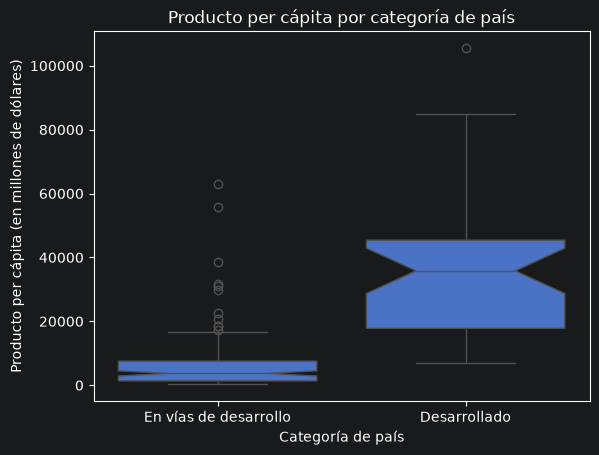

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(x='Desarrollado', y='GDP_per_capita', data=data_2015, notch=True)
plt.title("Producto per cápita por categoría de país")
plt.xlabel("Categoría de país")
plt.xticks(ticks=[0, 1], labels=["En vías de desarrollo", "Desarrollado"])
plt.ylabel("Producto per cápita (en millones de dólares)")
plt.show()

## Validamos normalidad en los datos (shapiro wiks o Smirnof

In [16]:
from scipy.stats import shapiro

# Separamos los datos en dos grupos, desarrollados y en vías de desarrollo
developed_countries = data_2015[data_2015['Desarrollado'] == 1]['GDP_per_capita']
developing_countries = data_2015[data_2015['Desarrollado'] == 0]['GDP_per_capita']

# Test de Shapiro-Wilk para países desarrollados
stat, p = shapiro(developed_countries)
print(f"Test de Shapiro-Wilk para países desarrollados: Estadístico={stat:.3f}, p-valor={p:.3f}")

# Test de Shapiro-Wilk para países en vías de desarrollo
stat, p = shapiro(developing_countries)
print(f"Test de Shapiro-Wilk para países en vías de desarrollo: Estadístico={stat:.3f}, p-valor={p:.3f}")

Test de Shapiro-Wilk para países desarrollados: Estadístico=0.917, p-valor=0.009
Test de Shapiro-Wilk para países en vías de desarrollo: Estadístico=0.606, p-valor=0.000


Bueno, parece que los datos no son normales, según este test. Tiremos un test de Kolmogorov-Smirnov, ya que estamos, para que vean como se usa. Importante: a diferencia del Shapiro-Wilk, este test es más general y menos potente para detectar desviaciones sutiles de normalidad, pero puede aplicarse a muestras más grandes.

In [17]:
from scipy.stats import kstest

# Test de Kolmogorov-Smirnov para países desarrollados
stat, p = kstest(developed_countries, 'norm')
print(f"Test de Kolmogorov-Smirnov para países desarrollados: Estadístico={stat:.3f}, p-valor={p:.3f}")

# Test de Kolmogorov-Smirnov para países en vías de desarrollo
stat, p = kstest(developing_countries, 'norm')
print(f"Test de Kolmogorov-Smirnov para países en vías de desarrollo: Estadístico={stat:.3f}, p-valor={p:.3f}")

Test de Kolmogorov-Smirnov para países desarrollados: Estadístico=1.000, p-valor=0.000
Test de Kolmogorov-Smirnov para países en vías de desarrollo: Estadístico=1.000, p-valor=0.000


## QQ plot de la hipotesis

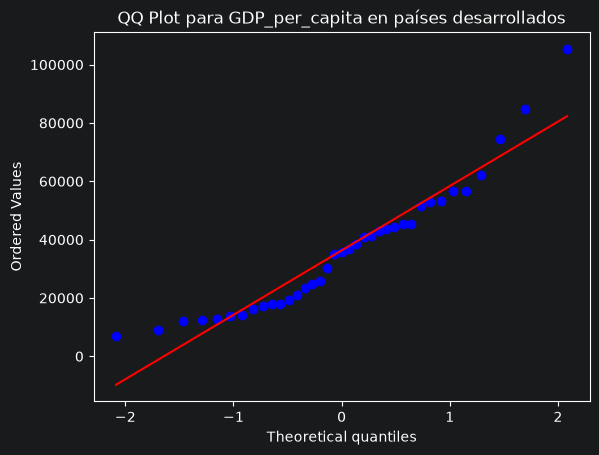

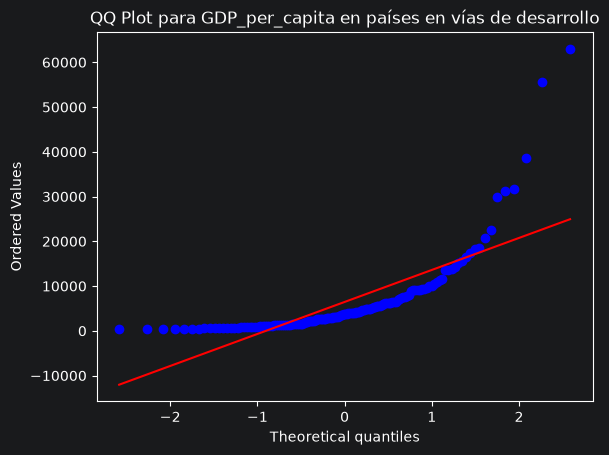

In [18]:
import matplotlib.pyplot as plt
import scipy.stats as stats

# QQ plot para países desarrollados
stats.probplot(developed_countries, dist="norm", plot=plt)
plt.title("QQ Plot para GDP_per_capita en países desarrollados")
plt.show()

# QQ plot para países en vías de desarrollo
stats.probplot(developing_countries, dist="norm", plot=plt)
plt.title("QQ Plot para GDP_per_capita en países en vías de desarrollo")
plt.show()

## Validamos Homocedasticidad (Levene(no normales) o Bartlett(normales))

In [19]:
stat, p = stats.levene(developed_countries, developing_countries)
print(f"Test de Levene para GDP_per_capita: Estadístico={stat:.3f}, p-valor={p:.3f}")

Test de Levene para GDP_per_capita: Estadístico=50.924, p-valor=0.000


Bueno, obtuvimos un p-valor menor a 0.05, por ende tenemos datos que no son homocedasticos!

## Vakudamos la Hipotesis con Kruskal Wallis

In [20]:
# Test de Kruskal-Wallis para comparar GDP_per_capita entre países desarrollados y en vías de desarrollo
stat, p = stats.kruskal(developed_countries, developing_countries)
print(f"Test de Kruskal-Wallis para GDP_per_capita: Estadístico={stat:.3f}, p-valor={p:.3f}")

# Interpretación de los resultados
alpha = 0.05  # Nivel de significancia
if p > alpha:
    print("No hay suficiente evidencia para rechazar la hipótesis nula.")
    print("No hay una diferencia significativa en el GDP_per_capita entre países desarrollados y en vías de desarrollo.")
else:
    print("Se rechaza la hipótesis nula.")
    print("Existe una diferencia significativa en el GDP_per_capita entre países desarrollados y en vías de desarrollo.")

Test de Kruskal-Wallis para GDP_per_capita: Estadístico=70.552, p-valor=0.000
Se rechaza la hipótesis nula.
Existe una diferencia significativa en el GDP_per_capita entre países desarrollados y en vías de desarrollo.


## si los países en vías de desarrollo gastan un menor porcentaje de su producto bruto en salud que los países desarrollados

In [33]:
import pandas as pd
dataset = pd.read_csv("Life Expectancy Data.csv")
dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 2938 entries, 0 to 2937
Data columns (total 22 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Country                          2938 non-null   str    
 1   Year                             2938 non-null   int64  
 2   Status                           2938 non-null   str    
 3   Life expectancy                  2928 non-null   float64
 4   Adult Mortality                  2928 non-null   float64
 5   infant deaths                    2938 non-null   int64  
 6   Alcohol                          2744 non-null   float64
 7   percentage expenditure           2938 non-null   float64
 8   Hepatitis B                      2385 non-null   float64
 9   Measles                          2938 non-null   int64  
 10   BMI                             2904 non-null   float64
 11  under-five deaths                2938 non-null   int64  
 12  Polio                          

In [34]:
dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 2938 entries, 0 to 2937
Data columns (total 22 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Country                          2938 non-null   str    
 1   Year                             2938 non-null   int64  
 2   Status                           2938 non-null   str    
 3   Life expectancy                  2928 non-null   float64
 4   Adult Mortality                  2928 non-null   float64
 5   infant deaths                    2938 non-null   int64  
 6   Alcohol                          2744 non-null   float64
 7   percentage expenditure           2938 non-null   float64
 8   Hepatitis B                      2385 non-null   float64
 9   Measles                          2938 non-null   int64  
 10   BMI                             2904 non-null   float64
 11  under-five deaths                2938 non-null   int64  
 12  Polio                          

In [35]:
dataset[["percentage expenditure", "Total expenditure"]].describe()

,percentage expenditure,Total expenditure
count,2938.000000,2712.00000
mean,738.251295,5.93819
std,1987.914858,2.49832
min,0.000000,0.37000
25%,4.685343,4.26000
50%,64.912906,5.75500
75%,441.534144,7.49250
max,19479.911610,17.60000


In [36]:
dataset["Status"].value_counts()

Status
Developing    2426
Developed      512
Name: count, dtype: int64

Developed (N=32), mean=7.55
Developing (N=159), mean=5.72
Normality Developed: p=0.0005
Normality Developing: p=0.0000
Levene: p=0.8088
T-test (less): p=2.7026e-05
Mann-Whitney (less): p=3.0882e-07


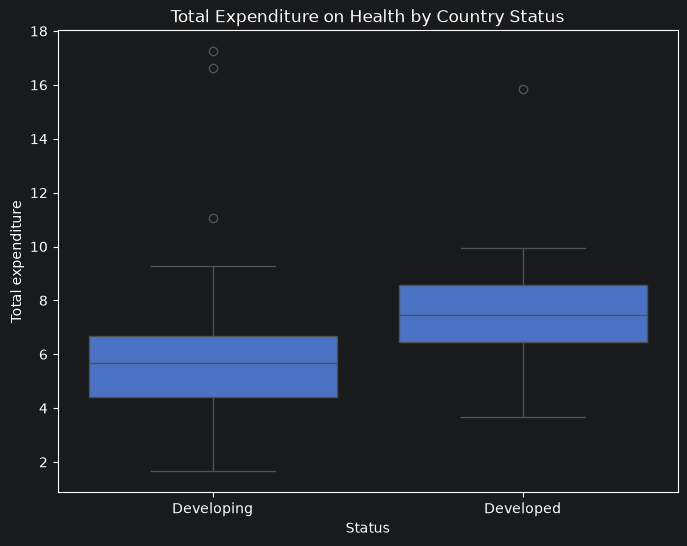

In [39]:
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

# Clean column names
dataset.columns = dataset.columns.str.strip()

# Aggregate by country to have independent observations
df_agg = dataset.groupby(['Country', 'Status'])['Total expenditure'].mean().reset_index()
df_agg = df_agg.dropna(subset=['Total expenditure'])

dev = df_agg[df_agg['Status'] == 'Developed']['Total expenditure']
undev = df_agg[df_agg['Status'] == 'Developing']['Total expenditure']

# 1. Normality
stat_dev, p_dev = stats.shapiro(dev)
stat_undev, p_undev = stats.shapiro(undev)

# 2. Variances
stat_lev, p_lev = stats.levene(dev, undev)

# 3. T-test (Welch's if unequal variance)
stat_t, p_t = stats.ttest_ind(undev, dev, alternative='less', equal_var=False)

# 4. Mann-Whitney
stat_mw, p_mw = stats.mannwhitneyu(undev, dev, alternative='less')

print(f"Developed (N={len(dev)}), mean={dev.mean():.2f}")
print(f"Developing (N={len(undev)}), mean={undev.mean():.2f}")
print(f"Normality Developed: p={p_dev:.4f}")
print(f"Normality Developing: p={p_undev:.4f}")
print(f"Levene: p={p_lev:.4f}")
print(f"T-test (less): p={p_t:.4e}")
print(f"Mann-Whitney (less): p={p_mw:.4e}")

# Save plot
plt.figure(figsize=(8,6))
sns.boxplot(x='Status', y='Total expenditure', data=df_agg)
plt.title('Total Expenditure on Health by Country Status')
plt.savefig('boxplot.png')


